# A13 工期不稳定时，怎样估计延期概率与安排缓冲？

用带相关性的模拟任务历史估计工期分布，保留任务依赖。比较把两天缓冲放在搭建前或项目末尾；缓冲只有通过预约机制才可能改变延期风险，不凭空缩短工作。

先修：B27、A04；概率分布、任务依赖、整行 bootstrap 与独立情景。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 历史数据与依赖图
六个任务：A方案；B采购和C审批都在A后；D搭建需B、C完成；E验收在D后；F宣传在A后。历史每行是一整个项目，同一项目的共同波动造成任务相关性。

In [2]:
import numpy as np,pandas as pd,json
rng=np.random.default_rng(113)
names=['A','B','C','D','E','F']; means=np.array([2,5,7,3,2,6])
def new_projects(n,random):
    shared=random.normal(0,0.14,(n,1))
    individual=random.normal(0,0.12,(n,6))
    return means*np.exp(shared+individual-(0.14**2+0.12**2)/2)
history=new_projects(100,rng)
history_frame=pd.DataFrame(history,columns=names); history_frame.to_csv(DATA_DIR/'simulated_project_history.csv',index=False)
estimated_mean=history.mean(axis=0)
nominal_ready=estimated_mean[0]+max(estimated_mean[1],estimated_mean[2])
deadline=nominal_ready+estimated_mean[3]+estimated_mean[4]+2


## 2. 用预约机制明确缓冲的作用
搭建队只有预约时点可立即开工，若准备晚于预约则额外等待 3 天重新预约。两种方案总预留均为 2 天：before 把两天放在搭建前，end 把两天留在最后。宣传并行，最终必须验收与宣传均完成。

In [3]:
def finish_times(durations,buffer_before):
    ready=durations[:,0]+np.maximum(durations[:,1],durations[:,2])
    slot=nominal_ready+buffer_before
    missed=ready>slot
    start_d=np.maximum(ready,slot)+3*missed
    finish_e=start_d+durations[:,3]+durations[:,4]
    finish_f=durations[:,0]+durations[:,5]
    return np.maximum(finish_e,finish_f),missed
tiny=np.array([[2,5,7,3,2,6]],dtype=float)
tiny_finish,_=finish_times(tiny,0)
assert tiny_finish[0]>=14


## 3. 用整行重抽样保留任务相关性
从历史项目中重抽整行，不能分别抽每列后声称保留了相关性。用 2000 个开发情景选择缓冲位置，固定准时目标，不在最终新项目上挑方案。

In [4]:
development=history[rng.integers(0,len(history),2000)]
policies={'end':0.0,'before':2.0}
development_results={}
for name,buffer_before in policies.items():
    finish,missed=finish_times(development,buffer_before)
    development_results[name]={'late_probability':float(np.mean(finish>deadline)),'mean_finish':float(finish.mean()),'missed_booking_rate':float(missed.mean())}
selected=min(development_results,key=lambda name:development_results[name]['late_probability'])


## 4. 独立未来情景验证并说明局限
最终 2000 个情景从同一已知模拟机制重新生成，不复用历史重抽样。报告不同缓冲方案的完工分布、延期率和重新预约率；对同一项目情景的延期指示作配对差值，用其标准误构造近似蒙特卡洛区间，判断微小差别是否只是模拟噪声。该区间不涵盖模型偏差；真实任务还要检验分布、依赖与预约规则。

In [5]:
future=new_projects(2000,np.random.default_rng(114))
future_results={}; rows=[]; finish_by_policy={}
for name,buffer_before in policies.items():
    finish,missed=finish_times(future,buffer_before); finish_by_policy[name]=finish
    future_results[name]={'late_probability':float(np.mean(finish>deadline)),'mean_finish':float(finish.mean()),'p90_finish':float(np.quantile(finish,0.9)),'missed_booking_rate':float(missed.mean())}
    rows.extend({'policy':name,'finish':float(f),'late':bool(f>deadline)} for f in finish)
metrics={'deadline':float(deadline),'selected_on_development':selected,'development':development_results,'independent_simulation':future_results,'simulation_only':True}
paired_difference=(finish_by_policy['before']>deadline).astype(float)-(finish_by_policy['end']>deadline).astype(float)
delta=float(paired_difference.mean()); monte_carlo_se=float(paired_difference.std(ddof=1)/np.sqrt(len(paired_difference)))
difference_interval=[delta-1.96*monte_carlo_se,delta+1.96*monte_carlo_se]
metrics['before_minus_end_late_probability']={'estimate':delta,'approx_95_monte_carlo_interval':difference_interval,'excludes_model_uncertainty':True}
pd.DataFrame(rows).to_csv(OUT_DIR/'finish_distribution.csv',index=False)
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
advice=f'开发情景选择缓冲方案 {selected}。共同承诺工期 {deadline:.2f} 天；独立模拟延期率 {future_results[selected]["late_probability"]:.1%}，90% 完工分位 {future_results[selected]["p90_finish"]:.2f} 天。前置缓冲会推迟预约，但降低错过搭建队的风险；若不存在 3 天重约等待，本结论需重新计算。历史仅为模拟，不代表真实项目可靠性。'
advice += f' 前置减末端方案的延期率差为 {delta:.2%}，共同随机情景下的近似 95% 蒙特卡洛区间为 [{difference_interval[0]:.2%}, {difference_interval[1]:.2%}]；该区间不涵盖建模偏差。'
if difference_interval[0]<=0<=difference_interval[1]:
    advice += ' 目前差异不足以说明哪个方案稳定降低延期率；需结合预约失败后果、成本与更多真实记录决定。'
(OUT_DIR/'决策建议.md').write_text('# 工期建议\n\n'+advice,encoding='utf-8')
for name,finish in finish_by_policy.items(): plt.hist(finish,bins=35,alpha=0.5,label=name,density=True)
plt.axvline(deadline,color='black',ls='--',label='承诺日期'); plt.legend(); plt.xlabel('完工天数'); plt.ylabel('密度'); plt.tight_layout(); plt.savefig(OUT_DIR/'completion.png'); plt.close(); print(metrics)


{'deadline': 16.174379145417845, 'selected_on_development': 'end', 'development': {'end': {'late_probability': 0.471, 'mean_finish': 16.149741325248, 'missed_booking_rate': 0.471}, 'before': {'late_probability': 0.492, 'mean_finish': 16.46304327325856, 'missed_booking_rate': 0.079}}, 'independent_simulation': {'end': {'late_probability': 0.4595, 'mean_finish': 16.13339112782704, 'p90_finish': 20.106908841698377, 'missed_booking_rate': 0.46}, 'before': {'late_probability': 0.46, 'mean_finish': 16.5573198637733, 'p90_finish': 19.526055838271578, 'missed_booking_rate': 0.103}}, 'simulation_only': True, 'before_minus_end_late_probability': {'estimate': 0.0005, 'approx_95_monte_carlo_interval': [-0.02113211256320042, 0.02213211256320042], 'excludes_model_uncertainty': True}}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

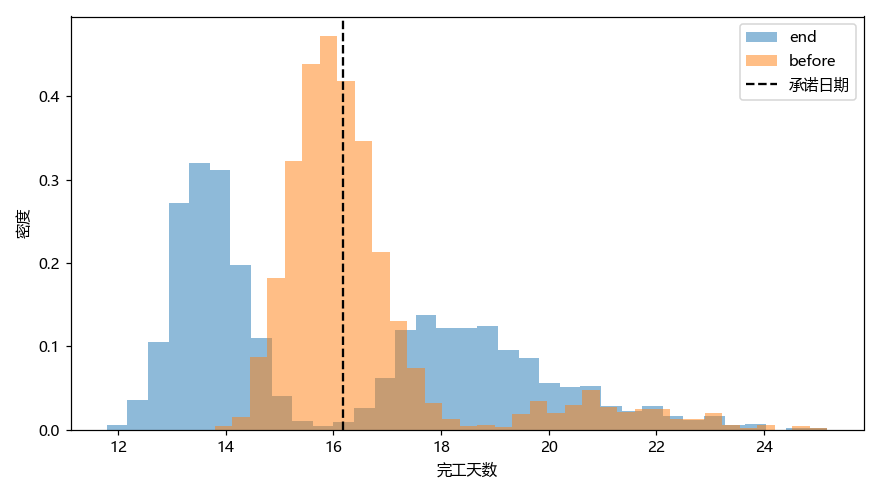

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
缓冲不是能自动缩短真实工时的资源。本例效应来自明确的预约失败机制；改规则就应重跑。2000 次模拟降低蒙特卡洛误差，不能消除建模偏差。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。